# Directional Coupler — Coupling Length via Even/Odd Supermode Analysis

Method, per Ansys/Lumerical's ["Evanescent waveguide couplers"](https://optics.ansys.com/hc/en-us/articles/360042304694-Evanescent-waveguide-couplers)
(meep's own eigenmode/MPB solver — no time-domain FDTD, no FECES solvers).

Two identical, individually single-mode waveguides placed close enough to interact
evanescently no longer have independent modes — the coupled cross-section instead
supports two "supermodes":

- even (symmetric) — effective index n_eff,even (higher)
- odd (antisymmetric) — effective index n_eff,odd (lower)

Launching light into just one waveguide excites an equal superposition of both
supermodes. Because they propagate at slightly different phase velocities, power beats
back and forth between the two physical waveguides as they co-propagate. The distance
for a full 100% transfer from one waveguide to the other — the coupling length — is

    L_c = lambda / (2 * |n_eff,even - n_eff,odd|)

and the fraction of power transferred to the other waveguide after propagating a
length L is

    T_cross(L) = sin^2(pi * L / (2 * L_c))

This notebook builds the SAME cross-section as the coupling region of
`directional_coupler_hybrid.py` (220 nm SOI, 0.45 um wide strips, 0.25 um gap), solves
for the two lowest-order eigenmodes of that cross-section with meep's own mode solver
(`meow.compute_modes_meep`, which wraps `mp.Simulation.get_eigenmode` — i.e. MPB) at
each wavelength, and reports L_c(wavelength). It also sweeps the gap at a fixed
wavelength to show the classic exponential falloff of coupling strength with
separation.

**Resolution sweep:** the whole analysis (wavelength sweep + gap sweep + plots) runs
once per entry in `RESOLUTIONS`, each with its own output subfolder and its own pair of
plots — so a mesh-convergence check is just a matter of comparing L_c across the
`res_*` subfolders.

Only reuses `feces.materials.SOI_220` for the Si/SiO2 dispersion + extrusion rules (so
the material model matches `directional_coupler_hybrid.py` exactly) — everything else
(GDS layout, meow calls, mode solving) is done directly, without going through any
FECES solver class.

In [9]:
import os

import numpy as np
import matplotlib.pyplot as plt

import meow as mw

from feces import extrude_polygons
from feces.materials import SOI_220

In [10]:
_HERE = os.getcwd()
output_dir = os.path.abspath(os.path.join(_HERE, "..", "..", "..", "example_output", "directional_coupler", "directional_coupler_mode"))
os.makedirs(output_dir, exist_ok=True)
print(f"Output directory: {output_dir}")

Output directory: /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode


In [11]:
# 1. Geometry / material constants — matches directional_coupler_hybrid.py's
#    coupling-region cross-section (220 nm SOI).
WAVEGUIDE_WIDTH = 0.45     # um, single-mode strip width
GAP_NOMINAL = 0.25         # um, edge-to-edge coupling gap used for the wavelength sweep
MATERIAL_STACK = SOI_220   # 220 nm Si on SiO2 — same stack as the hybrid example

MESH_WIDTH = 4.0           # um, lateral (y) extent of the mode-solve mesh
MESH_HEIGHT = 3.0          # um, vertical (z) extent — matches MaterialStack.sz

WL_MIN, WL_MAX, N_WL = 1.50, 1.60, 21   # matches directional_coupler_hybrid.py's C-band sweep
GAPS = [0.15, 0.20, 0.25, 0.30, 0.40, 0.50]   # um, secondary sweep at the center wavelength

# Mesh resolutions to run the whole analysis at, one output set each (see the
# run_for_resolution() cell below) — pts/um, isotropic (required — meep's
# resolution is a single scalar).
RESOLUTIONS = [20.0, 30.0, 40.0, 50.0, 60.0, 70, 80, 90, 100]

In [12]:
# 2. Cross-section builder — two parallel silicon strips, `gap` apart.
def build_cross_section(gap: float, wl: float, res: float) -> mw.CrossSection:
    """Waveguide/oxide polygons -> meow CrossSection for two coupled parallel strips.

    The "length" here is arbitrary (1 um) — a CrossSection is a single
    transverse slice, so nothing about it depends on propagation length.
    """
    pitch = WAVEGUIDE_WIDTH + gap
    yc0, yc1 = -pitch / 2, +pitch / 2
    length = 1.0

    wg_polys = [
        [(0, yc - WAVEGUIDE_WIDTH / 2), (length, yc - WAVEGUIDE_WIDTH / 2),
         (length, yc + WAVEGUIDE_WIDTH / 2), (0, yc + WAVEGUIDE_WIDTH / 2)]
        for yc in (yc0, yc1)
    ]
    ox_poly = [
        (0, -MESH_WIDTH / 2), (length, -MESH_WIDTH / 2),
        (length, MESH_WIDTH / 2), (0, MESH_WIDTH / 2),
    ]
    gds_polys = {(2, 0): wg_polys, (1, 0): [ox_poly]}

    structs = extrude_polygons(gds_polys, MATERIAL_STACK.extrusion_rules)
    mesh = mw.Mesh2D(
        x=np.linspace(-MESH_WIDTH / 2, MESH_WIDTH / 2, int(res * MESH_WIDTH) + 1),
        y=np.linspace(-MESH_HEIGHT / 2, MESH_HEIGHT / 2, int(res * MESH_HEIGHT) + 1),
    )
    cells = mw.create_cells(structures=structs, mesh=mesh, Ls=[length])
    env = mw.Environment(wl=float(wl), T=25.0)
    return mw.CrossSection.from_cell(cell=cells[0], env=env)

In [13]:
def supermode_indices(gap: float, wl: float, res: float):
    """Even/odd supermode effective indices via meep's own mode solver (MPB).

    compute_modes_meep already returns modes sorted by decreasing
    real(neff); for two coupled single-mode waveguides the top two bands
    are exactly the even (higher index, symmetric) and odd (lower index,
    antisymmetric) supermodes.
    """
    from meow import compute_modes_meep

    cs = build_cross_section(gap, wl, res)
    modes = compute_modes_meep(cs, num_modes=2)
    n_even, n_odd = sorted((float(np.real(m.neff)) for m in modes), reverse=True)
    return n_even, n_odd


def coupling_length(n_even: float, n_odd: float, wl: float) -> float:
    return wl / (2.0 * abs(n_even - n_odd))

In [14]:
def run_for_resolution(res: float, output_dir: str) -> dict:
    """Run the full wavelength + gap sweep at one mesh resolution, saving
    the raw data and both plots into their own res_<res>/ subfolder, and
    displaying the plots inline. Returns the swept arrays for further use."""
    res_dir = os.path.join(output_dir, f"res_{res:g}")
    os.makedirs(res_dir, exist_ok=True)
    print(f"\n{'='*70}\nResolution = {res:g} pts/um -> {res_dir}\n{'='*70}")

    # -- Wavelength sweep at the nominal gap ---------------------------------
    wavelengths = np.linspace(WL_MIN, WL_MAX, N_WL)
    print(f"Directional coupler supermode analysis — {WAVEGUIDE_WIDTH} um strips, "
          f"{GAP_NOMINAL} um gap, 220 nm SOI")
    print(f"Wavelength sweep: {wavelengths[0]:.3f} - {wavelengths[-1]:.3f} um ({len(wavelengths)} pts)\n")

    n_even_wl = np.zeros(N_WL)
    n_odd_wl = np.zeros(N_WL)
    for i, wl in enumerate(wavelengths):
        n_even_wl[i], n_odd_wl[i] = supermode_indices(GAP_NOMINAL, wl, res)

    Lc_wl = wavelengths / (2.0 * np.abs(n_even_wl - n_odd_wl))

    wl_c = wavelengths[len(wavelengths) // 2]
    idx_c = int(np.argmin(np.abs(wavelengths - wl_c)))
    print(f"At lambda = {wl_c:.3f} um: n_eff,even = {n_even_wl[idx_c]:.5f}, "
          f"n_eff,odd = {n_odd_wl[idx_c]:.5f}, delta_n = {n_even_wl[idx_c]-n_odd_wl[idx_c]:.5f}")
    print(f"  Coupling length L_c = {Lc_wl[idx_c]:.3f} um  "
          f"(100% cross-over at L = L_c; back to 'through' at L = 2*L_c)\n")

    # -- Gap sweep at the center wavelength ----------------------------------
    print(f"Gap sweep at lambda = {wl_c:.3f} um: {GAPS} um")
    n_even_gap = np.zeros(len(GAPS))
    n_odd_gap = np.zeros(len(GAPS))
    for i, gap in enumerate(GAPS):
        n_even_gap[i], n_odd_gap[i] = supermode_indices(gap, wl_c, res)

    Lc_gap = wl_c / (2.0 * np.abs(n_even_gap - n_odd_gap))
    for gap, Lc in zip(GAPS, Lc_gap):
        print(f"  gap = {gap:.2f} um  ->  L_c = {Lc:.3f} um")

    # -- Save data ------------------------------------------------------------
    np.savez(
        os.path.join(res_dir, "supermode_sweep.npz"),
        wavelengths=wavelengths, n_even_wl=n_even_wl, n_odd_wl=n_odd_wl, Lc_wl=Lc_wl,
        gaps=np.asarray(GAPS), n_even_gap=n_even_gap, n_odd_gap=n_odd_gap, Lc_gap=Lc_gap,
        waveguide_width=WAVEGUIDE_WIDTH, gap_nominal=GAP_NOMINAL, resolution=res,
    )
    print(f"\nData saved -> {res_dir}/supermode_sweep.npz")

    # -- Plots ------------------------------------------------------------
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    ax = axes[0]
    ax.plot(wavelengths, n_even_wl, label="n_eff, even (symmetric)", color="steelblue")
    ax.plot(wavelengths, n_odd_wl, label="n_eff, odd (antisymmetric)", color="darkorange", linestyle="--")
    ax.set_xlabel("Wavelength (um)")
    ax.set_ylabel("Effective index")
    ax.set_title(f"Supermode indices (gap={GAP_NOMINAL} um, res={res:g})")
    ax.legend(fontsize=8)
    ax.grid(True)

    ax = axes[1]
    ax.plot(wavelengths, Lc_wl, color="k", lw=1.5)
    ax.set_xlabel("Wavelength (um)")
    ax.set_ylabel("Coupling length L_c (um)")
    ax.set_title(f"Coupling length vs wavelength (gap={GAP_NOMINAL} um, res={res:g})")
    ax.grid(True)

    ax = axes[2]
    ax.semilogy(GAPS, Lc_gap, "o-", color="firebrick")
    ax.set_xlabel("Gap (um)")
    ax.set_ylabel("Coupling length L_c (um)")
    ax.set_title(f"Coupling length vs gap (lambda={wl_c:.2f} um, res={res:g})")
    ax.grid(True, which="both")

    plt.suptitle(f"Directional Coupler — Even/Odd Supermode Analysis (meep MPB, res={res:g})", fontsize=11)
    plt.tight_layout()
    fig.savefig(os.path.join(res_dir, "supermode_analysis.png"), dpi=300)
    plt.show()
    plt.close(fig)
    print(f"Supermode analysis plot saved -> {res_dir}/supermode_analysis.png")

    # -- Predicted power transfer vs length, at the nominal gap/center wavelength,
    #    over the same 0-60 um range directional_coupler_hybrid.py sweeps — lets
    #    you sanity-check that script's full FDTD/EME result against this much
    #    cheaper cross-section-only prediction.
    L_range = np.linspace(0.0, 60.0, 201)
    T_cross_pred = np.sin(np.pi * L_range / (2.0 * Lc_wl[idx_c])) ** 2
    T_through_pred = 1.0 - T_cross_pred

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(L_range, T_through_pred, label="Through (predicted)", color="steelblue")
    ax.plot(L_range, T_cross_pred, label="Cross (predicted)", color="darkorange", linestyle="--")
    ax.axvline(Lc_wl[idx_c], color="gray", linestyle=":", lw=0.8,
               label=f"L_c = {Lc_wl[idx_c]:.2f} um")
    ax.set_xlabel("Coupling length (um)")
    ax.set_ylabel("Predicted power transfer")
    ax.set_title(f"Predicted Through/Cross Power vs Length (lambda={wl_c:.2f} um, gap={GAP_NOMINAL} um, res={res:g})\n"
                 f"T_cross(L) = sin^2(pi*L / (2*L_c)) — compare against directional_coupler_hybrid.py's "
                 f"coupling_length_sweep.png")
    ax.legend(fontsize=8)
    ax.grid(True)
    ax.set_ylim(0, 1.05)
    plt.tight_layout()
    fig.savefig(os.path.join(res_dir, "predicted_power_transfer.png"), dpi=300)
    plt.show()
    plt.close(fig)
    print(f"Predicted power-transfer plot saved -> {res_dir}/predicted_power_transfer.png")

    return dict(
        wavelengths=wavelengths, n_even_wl=n_even_wl, n_odd_wl=n_odd_wl, Lc_wl=Lc_wl,
        n_even_gap=n_even_gap, n_odd_gap=n_odd_gap, Lc_gap=Lc_gap,
    )


Resolution = 20 pts/um -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_20
Directional coupler supermode analysis — 0.45 um strips, 0.25 um gap, 220 nm SOI
Wavelength sweep: 1.500 - 1.600 um (21 pts)



/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

At lambda = 1.550 um: n_eff,even = 2.24460, n_eff,odd = 2.21687, delta_n = 0.02773
  Coupling length L_c = 27.946 um  (100% cross-over at L = L_c; back to 'through' at L = 2*L_c)

Gap sweep at lambda = 1.550 um: [0.15, 0.2, 0.25, 0.3, 0.4, 0.5] um


/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

  gap = 0.15 um  ->  L_c = 12.692 um
  gap = 0.20 um  ->  L_c = 19.081 um
  gap = 0.25 um  ->  L_c = 27.946 um
  gap = 0.30 um  ->  L_c = 41.654 um
  gap = 0.40 um  ->  L_c = 89.627 um
  gap = 0.50 um  ->  L_c = 191.430 um

Data saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_20/supermode_sweep.npz


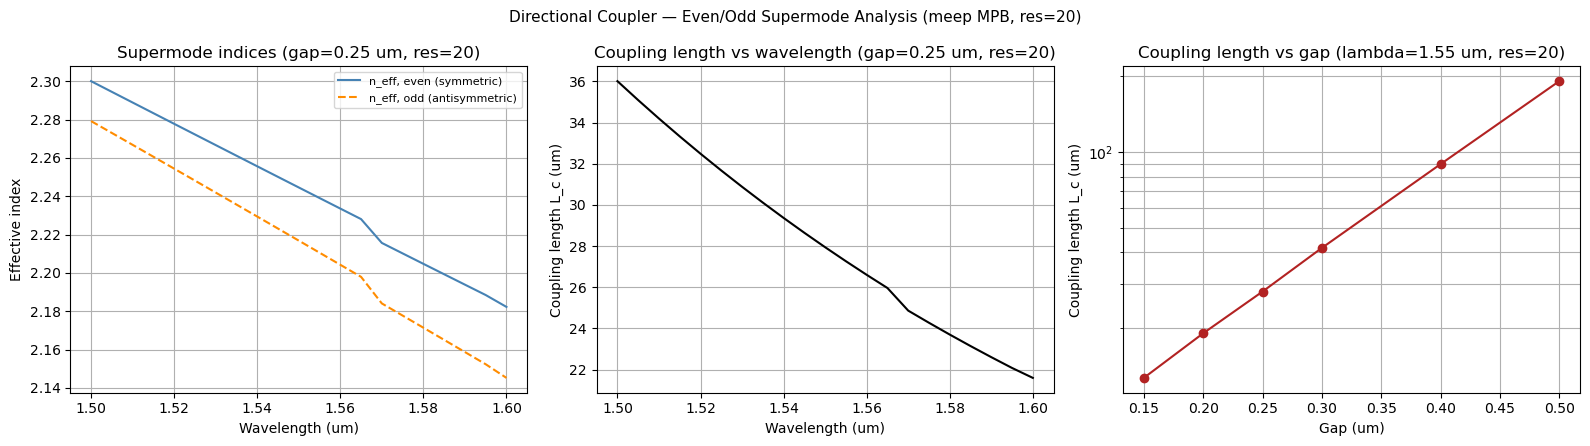

Supermode analysis plot saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_20/supermode_analysis.png


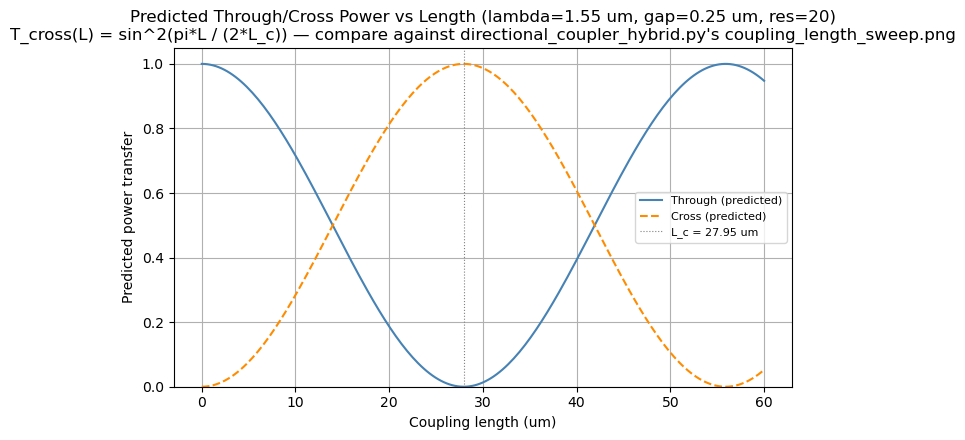

Predicted power-transfer plot saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_20/predicted_power_transfer.png

Resolution = 30 pts/um -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_30
Directional coupler supermode analysis — 0.45 um strips, 0.25 um gap, 220 nm SOI
Wavelength sweep: 1.500 - 1.600 um (21 pts)



/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

At lambda = 1.550 um: n_eff,even = 2.30240, n_eff,odd = 2.27793, delta_n = 0.02447
  Coupling length L_c = 31.670 um  (100% cross-over at L = L_c; back to 'through' at L = 2*L_c)

Gap sweep at lambda = 1.550 um: [0.15, 0.2, 0.25, 0.3, 0.4, 0.5] um


/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

  gap = 0.15 um  ->  L_c = 14.423 um
  gap = 0.20 um  ->  L_c = 20.346 um
  gap = 0.25 um  ->  L_c = 31.670 um
  gap = 0.30 um  ->  L_c = 47.802 um
  gap = 0.40 um  ->  L_c = 99.245 um
  gap = 0.50 um  ->  L_c = 228.419 um

Data saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_30/supermode_sweep.npz


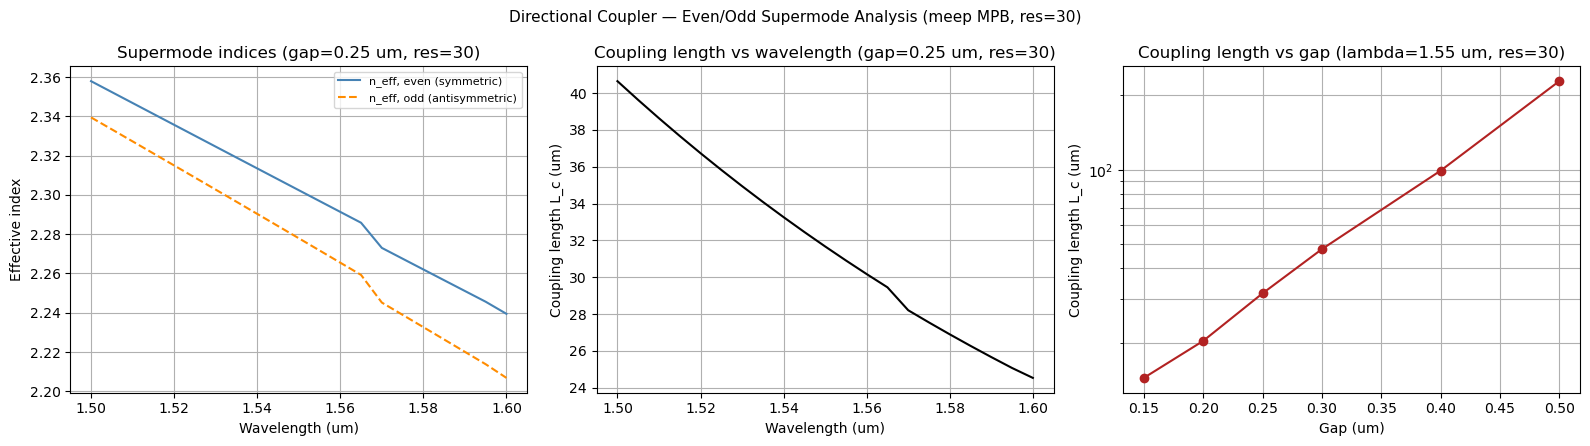

Supermode analysis plot saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_30/supermode_analysis.png


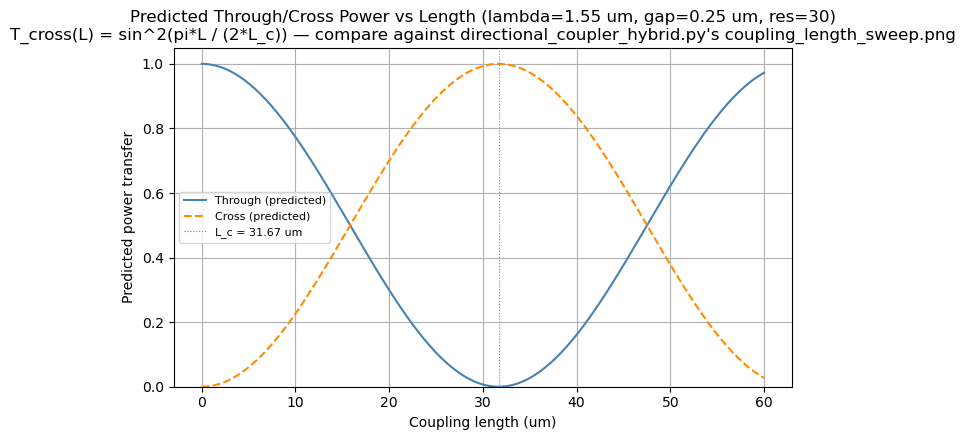

Predicted power-transfer plot saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_30/predicted_power_transfer.png

Resolution = 40 pts/um -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_40
Directional coupler supermode analysis — 0.45 um strips, 0.25 um gap, 220 nm SOI
Wavelength sweep: 1.500 - 1.600 um (21 pts)



/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

At lambda = 1.550 um: n_eff,even = 2.32507, n_eff,odd = 2.30149, delta_n = 0.02358
  Coupling length L_c = 32.863 um  (100% cross-over at L = L_c; back to 'through' at L = 2*L_c)

Gap sweep at lambda = 1.550 um: [0.15, 0.2, 0.25, 0.3, 0.4, 0.5] um


/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

  gap = 0.15 um  ->  L_c = 14.326 um
  gap = 0.20 um  ->  L_c = 21.833 um
  gap = 0.25 um  ->  L_c = 32.863 um
  gap = 0.30 um  ->  L_c = 49.179 um
  gap = 0.40 um  ->  L_c = 109.137 um
  gap = 0.50 um  ->  L_c = 240.300 um

Data saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_40/supermode_sweep.npz


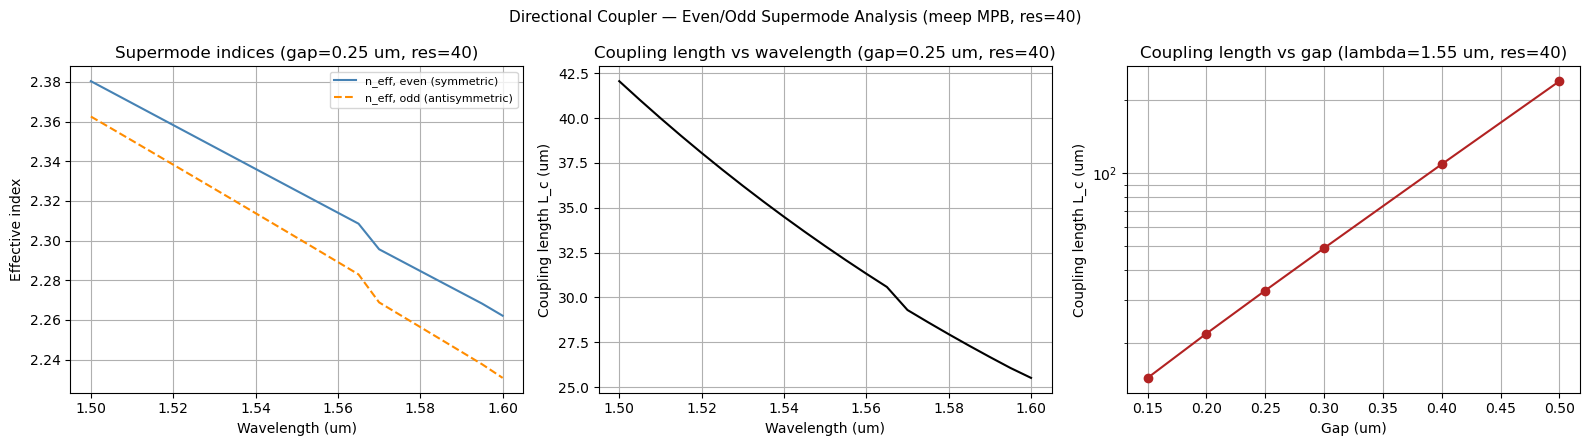

Supermode analysis plot saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_40/supermode_analysis.png


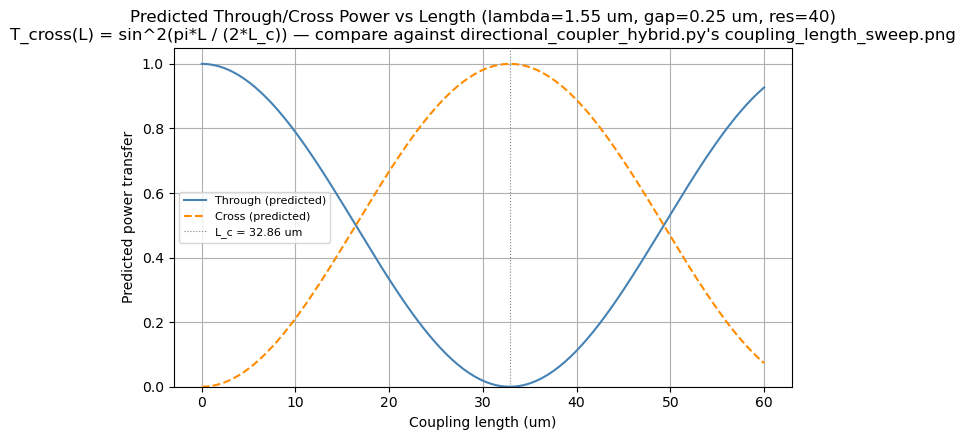

Predicted power-transfer plot saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_40/predicted_power_transfer.png

Resolution = 50 pts/um -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_50
Directional coupler supermode analysis — 0.45 um strips, 0.25 um gap, 220 nm SOI
Wavelength sweep: 1.500 - 1.600 um (21 pts)



/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

At lambda = 1.550 um: n_eff,even = 2.32900, n_eff,odd = 2.30626, delta_n = 0.02273
  Coupling length L_c = 34.090 um  (100% cross-over at L = L_c; back to 'through' at L = 2*L_c)

Gap sweep at lambda = 1.550 um: [0.15, 0.2, 0.25, 0.3, 0.4, 0.5] um


/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

  gap = 0.15 um  ->  L_c = 14.636 um
  gap = 0.20 um  ->  L_c = 22.087 um
  gap = 0.25 um  ->  L_c = 34.090 um
  gap = 0.30 um  ->  L_c = 50.523 um
  gap = 0.40 um  ->  L_c = 110.950 um
  gap = 0.50 um  ->  L_c = 248.291 um

Data saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_50/supermode_sweep.npz


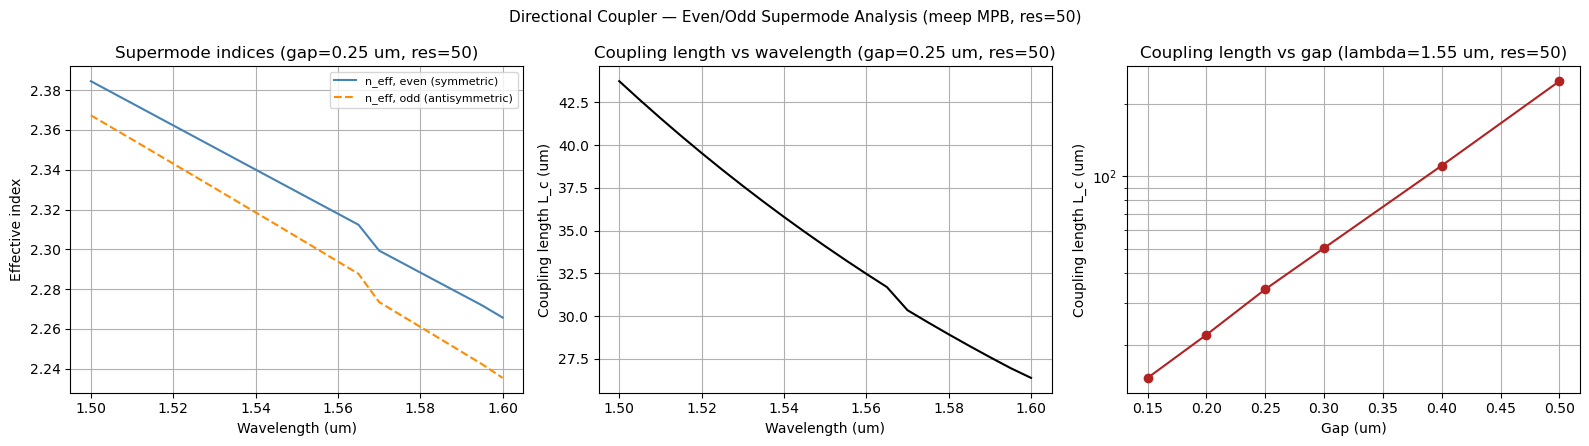

Supermode analysis plot saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_50/supermode_analysis.png


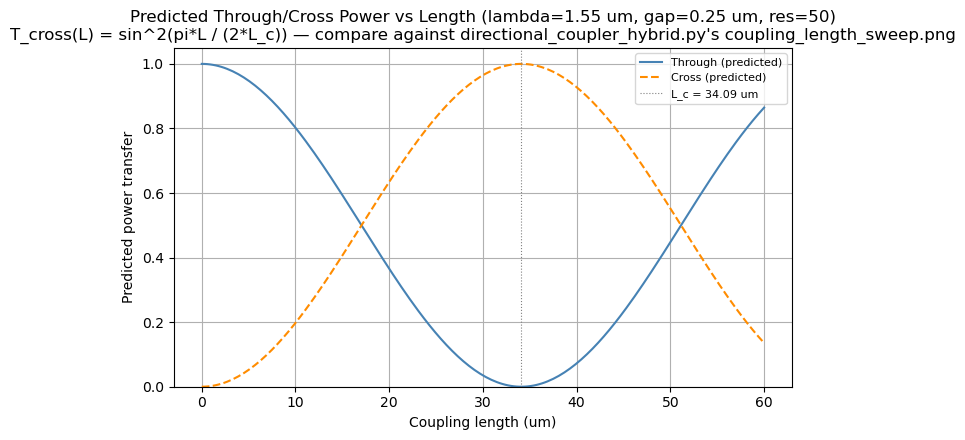

Predicted power-transfer plot saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_50/predicted_power_transfer.png

Resolution = 60 pts/um -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_60
Directional coupler supermode analysis — 0.45 um strips, 0.25 um gap, 220 nm SOI
Wavelength sweep: 1.500 - 1.600 um (21 pts)



/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

At lambda = 1.550 um: n_eff,even = 2.33641, n_eff,odd = 2.31359, delta_n = 0.02283
  Coupling length L_c = 33.954 um  (100% cross-over at L = L_c; back to 'through' at L = 2*L_c)

Gap sweep at lambda = 1.550 um: [0.15, 0.2, 0.25, 0.3, 0.4, 0.5] um


/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

  gap = 0.15 um  ->  L_c = 14.694 um
  gap = 0.20 um  ->  L_c = 22.693 um
  gap = 0.25 um  ->  L_c = 33.954 um
  gap = 0.30 um  ->  L_c = 51.573 um
  gap = 0.40 um  ->  L_c = 115.463 um
  gap = 0.50 um  ->  L_c = 256.472 um

Data saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_60/supermode_sweep.npz


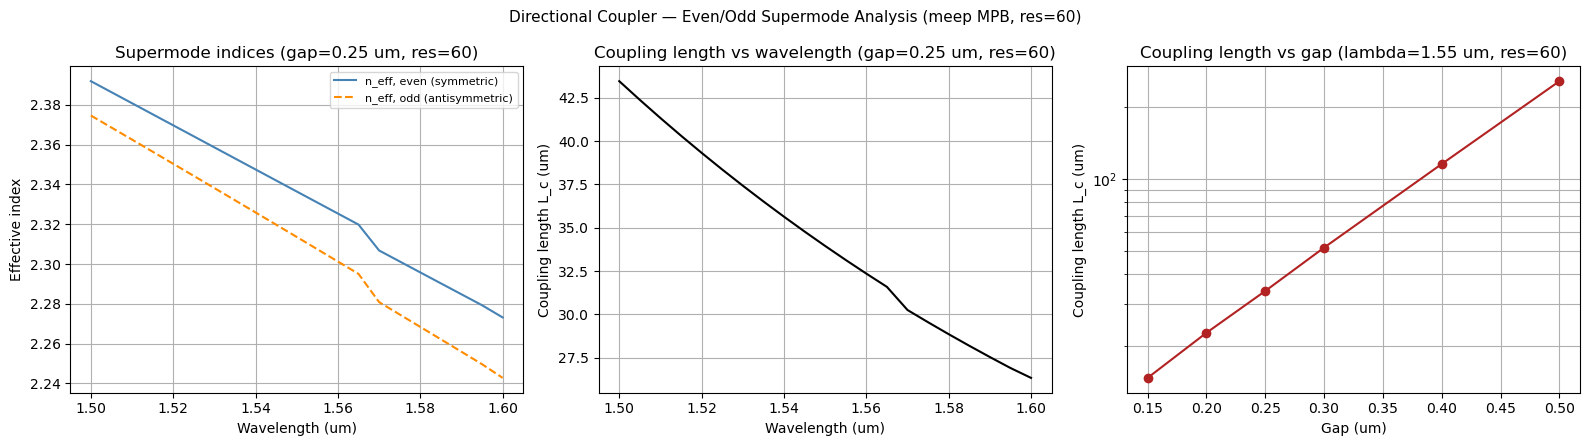

Supermode analysis plot saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_60/supermode_analysis.png


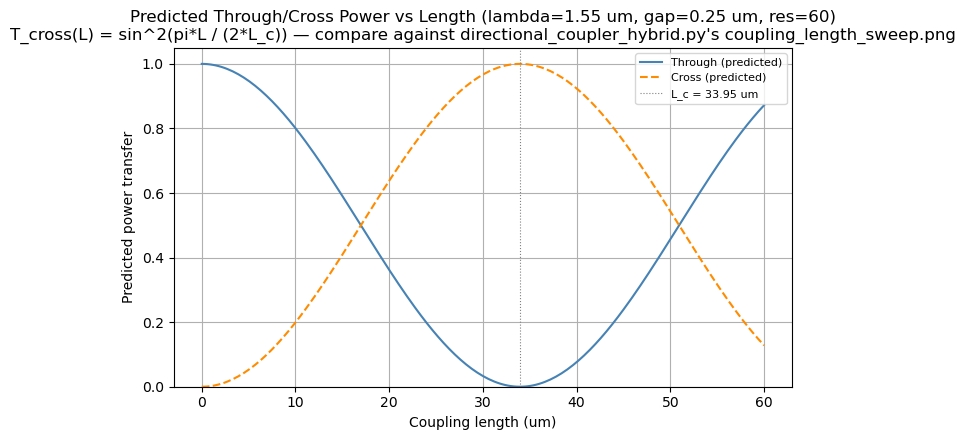

Predicted power-transfer plot saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_60/predicted_power_transfer.png

Resolution = 70 pts/um -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_70
Directional coupler supermode analysis — 0.45 um strips, 0.25 um gap, 220 nm SOI
Wavelength sweep: 1.500 - 1.600 um (21 pts)



/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

At lambda = 1.550 um: n_eff,even = 2.34523, n_eff,odd = 2.32297, delta_n = 0.02226
  Coupling length L_c = 34.819 um  (100% cross-over at L = L_c; back to 'through' at L = 2*L_c)

Gap sweep at lambda = 1.550 um: [0.15, 0.2, 0.25, 0.3, 0.4, 0.5] um


/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

  gap = 0.15 um  ->  L_c = 15.164 um
  gap = 0.20 um  ->  L_c = 22.751 um
  gap = 0.25 um  ->  L_c = 34.819 um
  gap = 0.30 um  ->  L_c = 52.461 um
  gap = 0.40 um  ->  L_c = 116.161 um
  gap = 0.50 um  ->  L_c = 261.950 um

Data saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_70/supermode_sweep.npz


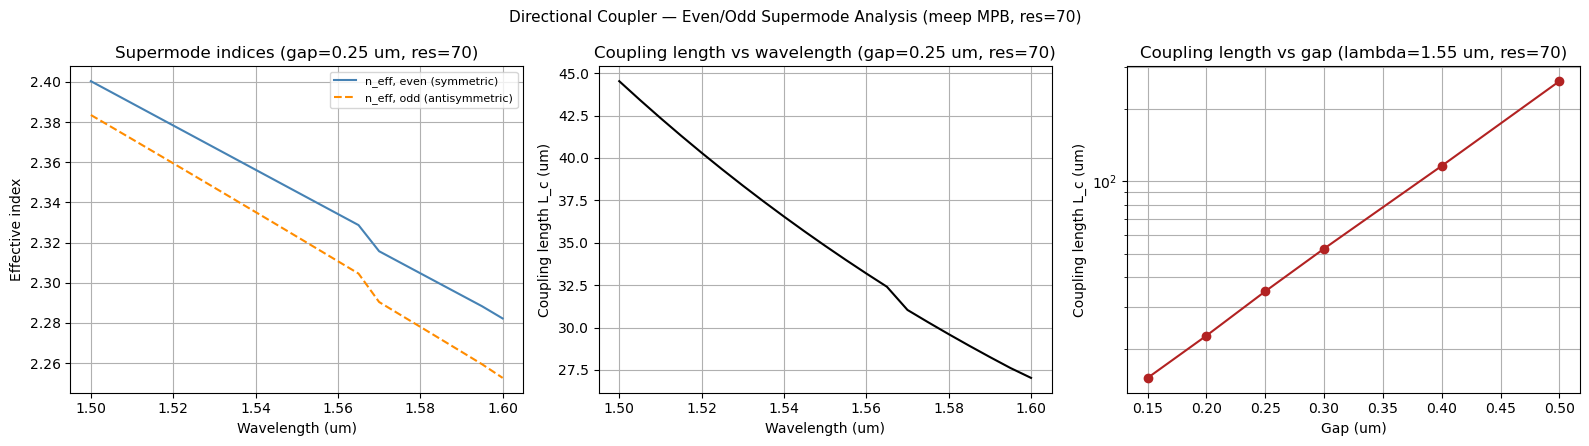

Supermode analysis plot saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_70/supermode_analysis.png


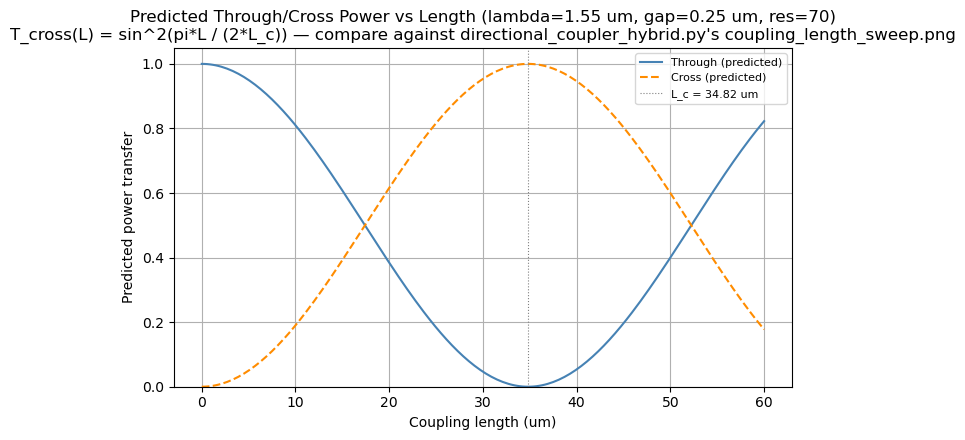

Predicted power-transfer plot saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_70/predicted_power_transfer.png

Resolution = 80 pts/um -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_80
Directional coupler supermode analysis — 0.45 um strips, 0.25 um gap, 220 nm SOI
Wavelength sweep: 1.500 - 1.600 um (21 pts)



/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

At lambda = 1.550 um: n_eff,even = 2.35086, n_eff,odd = 2.32881, delta_n = 0.02204
  Coupling length L_c = 35.159 um  (100% cross-over at L = L_c; back to 'through' at L = 2*L_c)

Gap sweep at lambda = 1.550 um: [0.15, 0.2, 0.25, 0.3, 0.4, 0.5] um


/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

  gap = 0.15 um  ->  L_c = 15.113 um
  gap = 0.20 um  ->  L_c = 23.199 um
  gap = 0.25 um  ->  L_c = 35.159 um
  gap = 0.30 um  ->  L_c = 52.974 um
  gap = 0.40 um  ->  L_c = 119.161 um
  gap = 0.50 um  ->  L_c = 265.939 um

Data saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_80/supermode_sweep.npz


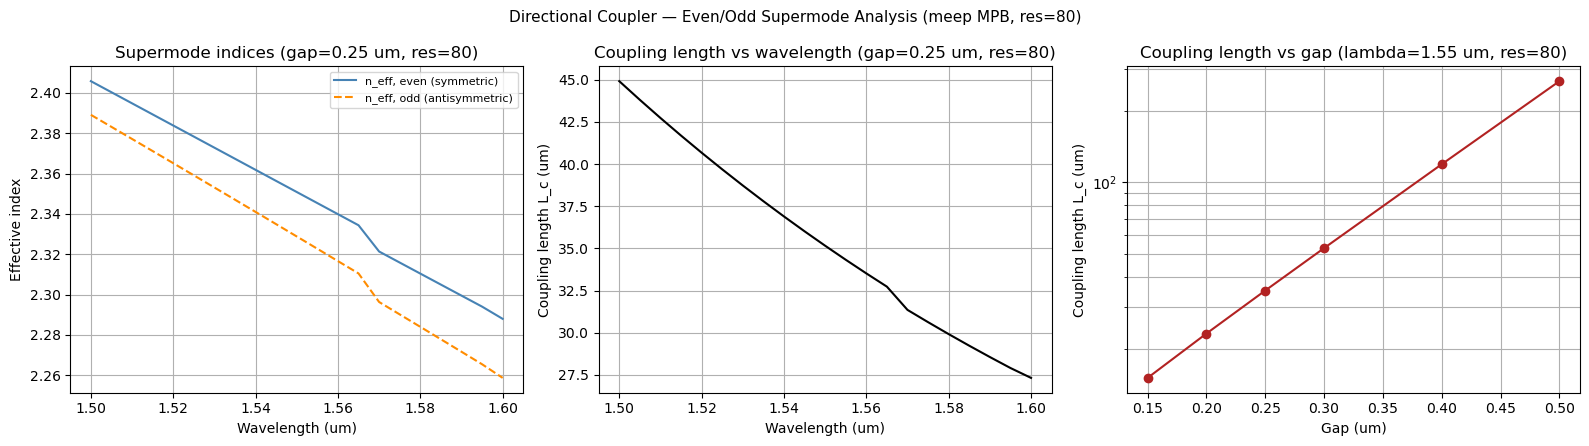

Supermode analysis plot saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_80/supermode_analysis.png


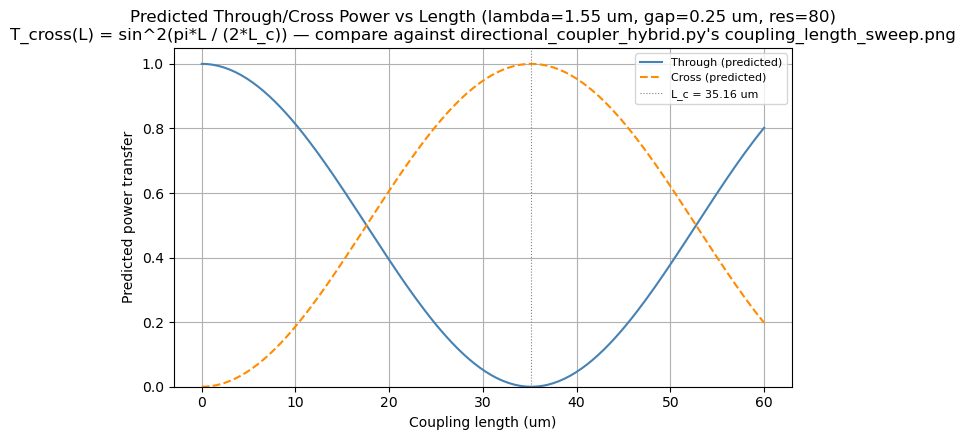

Predicted power-transfer plot saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_80/predicted_power_transfer.png

Resolution = 90 pts/um -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_90
Directional coupler supermode analysis — 0.45 um strips, 0.25 um gap, 220 nm SOI
Wavelength sweep: 1.500 - 1.600 um (21 pts)



/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

At lambda = 1.550 um: n_eff,even = 2.35211, n_eff,odd = 2.33026, delta_n = 0.02185
  Coupling length L_c = 35.465 um  (100% cross-over at L = L_c; back to 'through' at L = 2*L_c)

Gap sweep at lambda = 1.550 um: [0.15, 0.2, 0.25, 0.3, 0.4, 0.5] um


/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

  gap = 0.15 um  ->  L_c = 15.129 um
  gap = 0.20 um  ->  L_c = 23.172 um
  gap = 0.25 um  ->  L_c = 35.465 um
  gap = 0.30 um  ->  L_c = 53.346 um
  gap = 0.40 um  ->  L_c = 119.103 um
  gap = 0.50 um  ->  L_c = 268.109 um

Data saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_90/supermode_sweep.npz


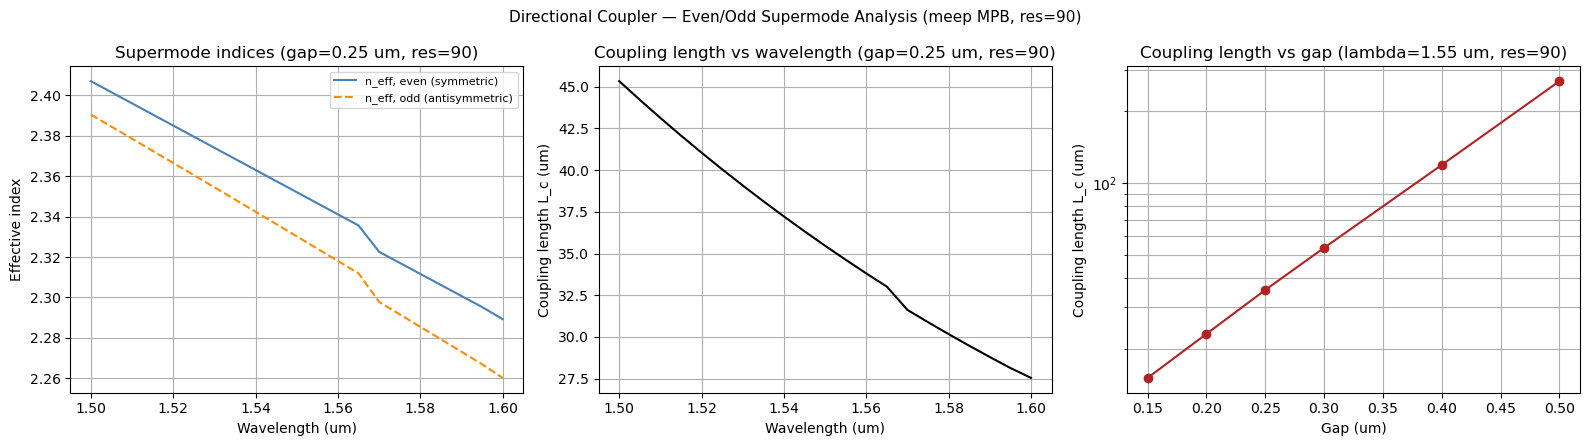

Supermode analysis plot saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_90/supermode_analysis.png


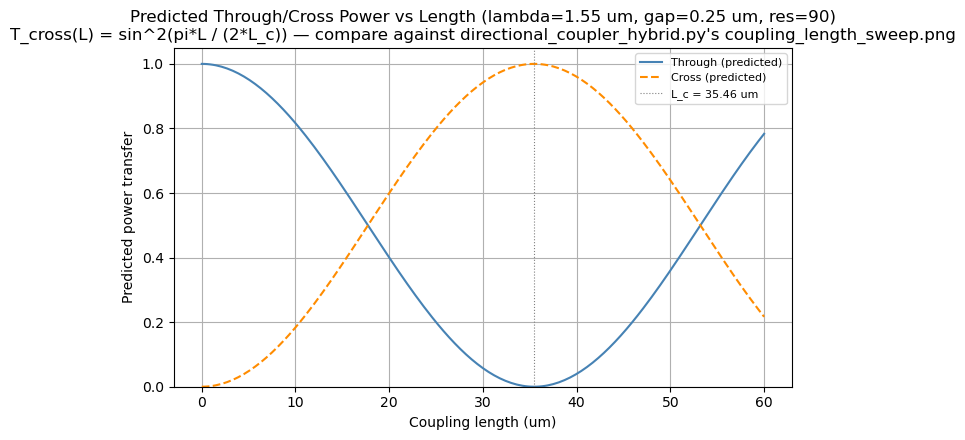

/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)


Predicted power-transfer plot saved -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_90/predicted_power_transfer.png

Resolution = 100 pts/um -> /Users/jhiesener/Documents/shit/example_output/directional_coupler/directional_coupler_mode/res_100
Directional coupler supermode analysis — 0.45 um strips, 0.25 um gap, 220 nm SOI
Wavelength sweep: 1.500 - 1.600 um (21 pts)



/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4457: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep.create_structure(cell_size, dft_data_list_, pml_1d_vols_, pml_2d_vols_, pml_3d_vols_, absorber_vols_, gv, br, sym, num_chunks, Courant, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_s, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/__init__.py:4460: ComplexWarning: Casting complex values to real discards the imaginary part
  return _meep._set_materials(s, cell_size, gv, use_anisotropic_averaging, tol, maxeval, gobj_list, center, _ensure_periodicity, _default_material, alist, extra_materials, split_chunks_evenly, set_materials, existing_geps, output_chunk_costs, my_bp)
/Users/jhiesener/miniconda3/envs/jmh/lib/python3.13/site-packages/meep/_

In [ ]:
# 3. Run the analysis once per resolution in RESOLUTIONS — each gets its own
#    res_<res>/ output subfolder (data + plots), so comparing L_c across
#    subfolders is a quick mesh-convergence check.
results_by_resolution = {}
for res in RESOLUTIONS:
    results_by_resolution[res] = run_for_resolution(res, output_dir)

In [ ]:
# 4. Quick convergence check — L_c at the center wavelength/nominal gap vs
#    resolution (does the previous cell's per-resolution result actually
#    stop changing as the mesh gets finer?).
idx_c = N_WL // 2
print("Resolution (pts/um)   L_c at nominal gap/center wavelength (um)")
for res in RESOLUTIONS:
    Lc = results_by_resolution[res]["Lc_wl"][idx_c]
    print(f"  {res:6g}                {Lc:.4f}")

Resolution (pts/um)   L_c at nominal gap/center wavelength (um)
      20                27.9447
      30                31.6696
      40                32.8625
      50                34.0892
      60                33.9531
